# Домашнее задание: Ad-hoc аналитика


In [19]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import duckdb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

DATA = Path("adhoc_lecture_handout/data")
if not DATA.exists():
    DATA = Path("data")

con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    df = pd.read_csv(DATA / filename)
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")
employer_spend = register_csv("employer_spend", "employer_spend.csv")

def sql(query: str) -> pd.DataFrame:
    return con.execute(query).df()

def wilson_ci(successes: float, n: float, z: float = 1.96):
    if n <= 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return max(0.0, center - margin), min(1.0, center + margin)

def summarize_dq(df: pd.DataFrame, key_cols=None) -> pd.DataFrame:
    rows = [{"проверка": "всего строк", "значение": len(df)}]
    for c in df.columns:
        if df[c].isna().sum() > 0:
            rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        rows.append({"проверка": f"дубли: {'+'.join(key_cols)}", "значение": int(df.duplicated(key_cols).sum())})
    return pd.DataFrame(rows)


## Задание 1. ТЗ по семи вопросам до SQL

| Вопрос ТЗ | Формулировка |
|---|---|
| 1. Проблема | 20 июля на Android кликабельность формата top_search подскочила до 9.4% при обычной норме около 3% |
| 2. Цель | Выяснить причину всплеска: технический сбой трекинга или реальные действия соискателей |
| 3. Гипотеза | Если сбой, клики зациклены, соискателей мало, откликов нет. Если реальный интерес, соискатели разные, есть нормальные отклики |
| 4. Метрика | Кликабельность с доверительным интервалом Уилсона, конверсия из клика в отклик, число уникальных пользователей и вакансий |
| 5. Период | Июль 2026 года, сравниваем 20 июля с обычной базой до и после |
| 6. Сегменты | Android против iOS и веба, а также соседний формат top_boost |
| 7. Решение | Если сбой логирования, отдаем задачу разработчикам SDK и убираем день из отчетов. Если реальный эффект, логи не трогаем, запрашиваем контекст у мобильной команды |


## Задание 2. Выбор ступени глубины

Выбираю среднюю ступень под названием Разбор. 

Цена ошибки здесь средняя. Если ошибочно решить, что сломалось логирование, разработчики потратят рабочее время на поиск несуществующего бага в коде SDK. Если же без проверки раскатать новый формат на проде, можно ухудшить поиск соискателям и потерять деньги. 

Быстрой прикидки на пару часов тут мало, так как надо проверить всю воронку до отклика. А глубокий разбор на неделю ради разового однодневного всплеска не требуется.


## Задание 3. Качество данных

Сначала проверяем пропуски, дубли и оторванные события.


In [20]:
display(summarize_dq(impressions, key_cols=["impression_id"]))
display(summarize_dq(clicks, key_cols=["click_id"]))
display(summarize_dq(responses, key_cols=["response_id"]))

orphans = (~clicks["impression_id"].isin(impressions["impression_id"])).sum()
print("Кликов без показов:", orphans)


,проверка,значение
0,всего строк,80000
1,дубли: impression_id,0


,проверка,значение
0,всего строк,3837
1,дубли: click_id,0


,проверка,значение
0,всего строк,421
1,дубли: response_id,0


Кликов без показов: 0


Пропусков и дублей нет, связность показов и кликов полная. 

Теперь смотрим детализацию вокруг 20 июля на Android: число кликов, уникальных людей, вакансий и откликов.


In [21]:
sql('''
SELECT
    c.event_date,
    COUNT(c.click_id) AS clicks,
    COUNT(DISTINCT c.hhuid) AS unique_users,
    COUNT(DISTINCT c.vacancy_id) AS unique_vacancies,
    COUNT(DISTINCT r.response_id) AS responses,
    ROUND(COUNT(DISTINCT r.response_id)::FLOAT / COUNT(c.click_id) * 100, 1) AS cvr_pct
FROM clicks c
LEFT JOIN responses r ON c.click_id = r.click_id
WHERE c.platform = 'ANDROID'
  AND c.product = 'top_search'
  AND c.event_date BETWEEN '2026-07-18' AND '2026-07-22'
GROUP BY 1
ORDER BY 1
''')


,event_date,clicks,unique_users,unique_vacancies,responses,cvr_pct
0,2026-07-18,11,11,11,3,27.299999
1,2026-07-19,11,11,11,2,18.200001
2,2026-07-20,36,36,36,4,11.100000
3,2026-07-21,7,7,7,0,0.000000
4,2026-07-22,15,15,15,5,33.299999


20 июля было ровно 36 кликов от 36 уникальных соискателей по 36 разным вакансиям. Накрутки от одного пользователя нет. Из этих кликов получилось 4 реальных отклика, конверсия вышла 11.1%. При техническом задвоении логов откликов было бы ноль. Данные чистые, сбоя трекинга нет.


## Задание 4. График с доверительным интервалом и график с распределением

Первый график: динамика кликабельности top_search на Android с 95% доверительным интервалом Уилсона.


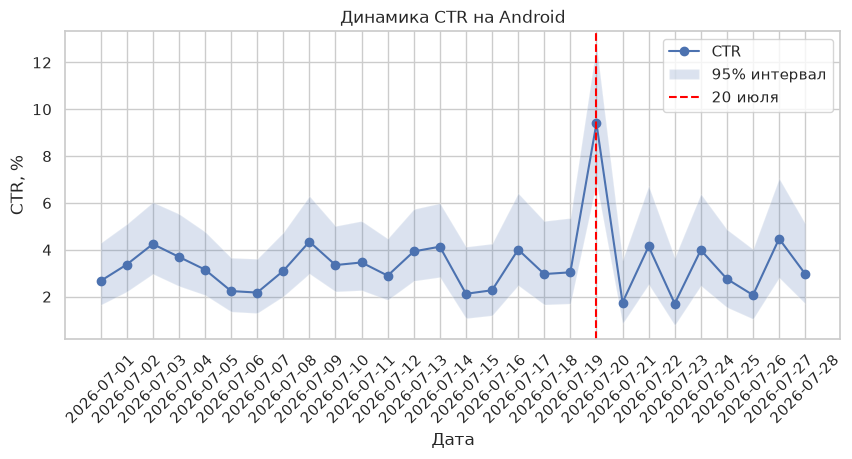

In [22]:
daily = sql('''
SELECT
    i.event_date,
    COUNT(*) AS impressions,
    COUNT(c.click_id) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.platform = 'ANDROID' AND i.product = 'top_search'
GROUP BY 1
ORDER BY 1
''')

daily["ctr"] = daily["clicks"] / daily["impressions"]
cis = [wilson_ci(k, n) for k, n in zip(daily["clicks"], daily["impressions"])]
daily["ci_low"] = [c[0] for c in cis]
daily["ci_high"] = [c[1] for c in cis]

plt.figure(figsize=(10, 4))
plt.plot(daily["event_date"], daily["ctr"] * 100, marker="o", label="CTR")
plt.fill_between(daily["event_date"], daily["ci_low"] * 100, daily["ci_high"] * 100, alpha=0.2, label="95% интервал")
plt.axvline("2026-07-20", color="red", linestyle="--", label="20 июля")
plt.title("Динамика CTR на Android")
plt.xlabel("Дата")
plt.ylabel("CTR, %")
plt.xticks(rotation=45)
plt.legend()
plt.show()


Нижняя граница интервала 20 июля находится около 6.9%, она выше верхних границ обычных дней. Скачок статистически значимый.

Второй график: распределение дневного CTR по платформам.


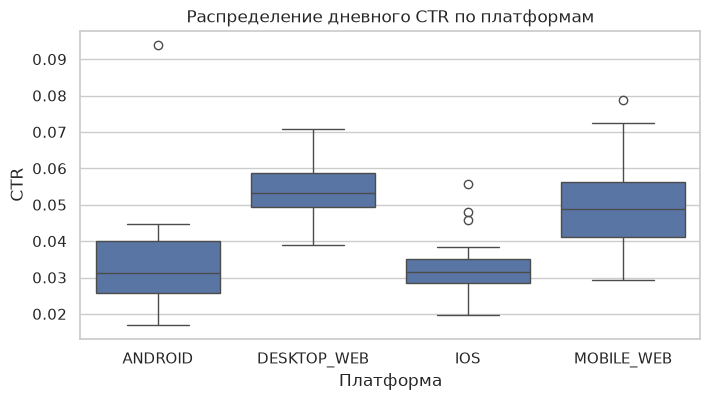

In [23]:
dist_daily = sql('''
SELECT
    i.event_date,
    i.platform,
    COUNT(*) AS impressions,
    COUNT(c.click_id) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_search'
GROUP BY 1, 2
''')
dist_daily["ctr"] = dist_daily["clicks"] / dist_daily["impressions"]

plt.figure(figsize=(8, 4))
sns.boxplot(data=dist_daily, x="platform", y="ctr")
plt.title("Распределение дневного CTR по платформам")
plt.ylabel("CTR")
plt.xlabel("Платформа")
plt.show()


На распределении видно, что точка 9.4% на Android является единственным экстремальным выбросом.


## Задание 5. Вывод в виде действия

Логирование не чиним, мобильных разработчиков не отвлекаем. Формат показа на Android прямо сейчас не меняем, так как всплеск был разовым и уже 21 июля кликабельность вернулась в норму. 

Действие для аналитика: пойти к мобильной команде и запросить список релизов, push-рассылок и конфиг-флагов за 20 июля.

Что подтвердили данные: все 36 кликов сделали 36 разных пользователей по 36 разным вакансиям, и они дали 4 отклика с конверсией 11.1%. Это действия живых людей, а не поломка логов.


## Задание 6. Ограничения

Всплеск продолжался всего один день, поэтому долгосрочный эффект оценить нельзя.

В имеющихся таблицах нет логов сборок приложения и push-рассылок, поэтому точную внешнюю причину всплеска по одним лишь кликам не установить.

Количество откликов за этот день небольшое, всего 4 штуки, поэтому конверсия имеет широкий доверительный интервал.


## Задание 7, бонус. Связка с динамикой расхода после 15 июля

Смотрим, как изменились расходы работодателей после запуска формата top_boost 15 июля.


In [24]:
sql('''
SELECT
    product,
    CASE WHEN event_date < '2026-07-15' THEN 'до 15 июля' ELSE 'после 15 июля' END AS period,
    ROUND(SUM(net_spend) / 1e6, 2) AS total_spend_mln,
    ROUND(AVG(net_spend) / 1e3, 1) AS avg_daily_k
FROM product_daily
GROUP BY 1, 2
ORDER BY 1, 2 DESC
''')


,product,period,total_spend_mln,avg_daily_k
0,top_boost,после 15 июля,5.73,68.2
1,top_search,после 15 июля,16.05,191.0
2,top_search,до 15 июля,19.28,229.5


После 15 июля дневной расход на top_search снизился с 229 до 191 тысячи рублей, но top_boost стал приносить 68 тысяч рублей в день. Суммарная дневная выручка выросла примерно на 30 тысяч рублей в день.

20 июля на Android синхронно выросли клики и отклики по обоим форматам. Это подтверждает, что в первые дни после запуска шла перенастройка выдачи и выросла активность соискателей, а не сломались логи приложения.
